In [1]:
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

from features import add_features

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
IMAGES = ROOT / "images"
MODEL_PATH = ROOT / "models" / "pd_model.joblib"

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])

loans = pd.read_sql("SELECT * FROM loans", engine)
saved = joblib.load(MODEL_PATH)
print(loans.shape)

(2260668, 42)


### Score every loan
Expected loss (EL) for each loan, at the day it was issued:

**EL = PD x exposure at default (share of the amount still owed) x loss given default x amount funded**

Realized loss for a matured loan is the principal still owed at default, minus net recoveries.

In [2]:
loans["pd_raw"] = saved["model"].predict_proba(add_features(loans))[:, 1]

loss_per_dollar = {term: s["ead_factor"] * s["lgd"] for term, s in saved["severity"].items()}
loans["loss_per_dollar"] = loans["term"].map(loss_per_dollar)
loans["expected_loss_raw"] = loans["pd_raw"] * loans["loss_per_dollar"] * loans["funded_amnt"]

judged = loans["bad"].notna()
defaulted = loans["bad"].fillna(0).astype(int) == 1
loans["realized_loss"] = np.where(
    defaulted,
    loans["funded_amnt"] - loans["total_rec_prncp"] - (loans["recoveries"] - loans["collection_recovery_fee"]),
    0.0,
)
loans[["pd_raw", "expected_loss_raw"]].describe().round(3)

,pd_raw,expected_loss_raw
count,2260668.000,2260668.000
mean,0.161,1471.356
std,0.101,1571.868
min,0.003,2.111
25%,0.083,388.193
50%,0.142,868.456
75%,0.220,2029.109
max,0.767,17666.549


### Backtest: 2015-2016 loans
Compare the model's expected loss with what actually happened on the out-of-time test loans.

In [3]:
def backtest(df, expected_col):
    table = df.groupby("grade").agg(
        loans=("id", "size"),
        funded=("funded_amnt", "sum"),
        expected_loss=(expected_col, "sum"),
        realized_loss=("realized_loss", "sum"),
    )
    table.loc["All"] = table.sum()
    table["expected_pct"] = (table["expected_loss"] / table["funded"] * 100).round(2)
    table["realized_pct"] = (table["realized_loss"] / table["funded"] * 100).round(2)
    table["realized_vs_expected"] = (table["realized_loss"] / table["expected_loss"]).round(2)
    table[["funded", "expected_loss", "realized_loss"]] = (table[["funded", "expected_loss", "realized_loss"]] / 1e6).round(1)
    return table.rename(columns={"funded": "funded_m", "expected_loss": "expected_loss_m", "realized_loss": "realized_loss_m"})


recent = judged & (loans["issue_year"] >= 2015)
backtest(loans[recent], "expected_loss_raw")

,loans,funded_m,expected_loss_m,realized_loss_m,expected_pct,realized_pct,realized_vs_expected
grade,,,,,,,
A,93011.0,1354.6,32.3,32.8,2.38,2.42,1.02
B,122710.0,1545.9,81.3,91.5,5.26,5.92,1.13
C,100212.0,1224.3,107.9,131.1,8.82,10.70,1.21
D,41606.0,522.5,61.2,83.8,11.72,16.04,1.37
E,12575.0,160.8,23.7,34.4,14.73,21.40,1.45
F,2214.0,23.8,4.2,6.8,17.77,28.72,1.62
G,483.0,4.9,1.0,1.7,19.83,35.41,1.79
All,372811.0,4836.8,311.6,382.1,6.44,7.90,1.23


### Finding: backtest
On loans it never saw, the model expected losses of 6.44% of the amount funded. 7.90% was actually lost,
23% more. The miss is small for grade A (realized/expected 1.02) and grows steadily with risk, to 1.79 for
grade G. Two things changed: more borrowers defaulted than the model expected (the drift found in
notebook 05), and the riskier grades got worse the most. This is exactly what a backtest is for: catching
a model that was right about the past before it is used on the future.

### Recalibrate to the latest matured vintages
Once the 2015-2016 outcomes are known, a lender would update the model before using it on the loans still
running. Two updates:

1. **PD scale.** Fit a one-variable logistic regression of the 2015-2016 outcomes on the model's log-odds
   (an intercept and a slope). The intercept fixes the overall level. The slope lets the riskier end move
   more than the safer end, which the backtest shows is needed. A positive slope never reorders loans, so
   the model's ranking stays exactly as it was.
2. **Loss severity.** Re-estimate exposure at default and LGD on every matured default, 2007-2016.

After this the 2015-2016 backtest is no longer out-of-sample. It only checks that the fit holds across
grades. It also assumes 60-month loans drifted like 36-month loans, since no 60-month loan from 2015 or
later has matured yet.

In [4]:
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression

calibrator = LogisticRegression(C=1e6)
calibrator.fit(logit(loans.loc[recent, ["pd_raw"]]), loans.loc[recent, "bad"].astype(int))
calibration = {"intercept": float(calibrator.intercept_[0]), "slope": float(calibrator.coef_[0, 0])}
loans["pd"] = expit(calibration["intercept"] + calibration["slope"] * logit(loans["pd_raw"]))

all_defaults = loans[defaulted].assign(
    ead=lambda d: d["funded_amnt"] - d["total_rec_prncp"],
    net_recovery=lambda d: d["recoveries"] - d["collection_recovery_fee"],
).groupby("term")[["funded_amnt", "ead", "net_recovery"]].sum()
severity_recalibrated = {
    term: {"ead_factor": row["ead"] / row["funded_amnt"], "lgd": 1 - row["net_recovery"] / row["ead"]}
    for term, row in all_defaults.iterrows()
}
loans["loss_per_dollar_recalibrated"] = loans["term"].map(
    {term: s["ead_factor"] * s["lgd"] for term, s in severity_recalibrated.items()}
)
loans["expected_loss"] = loans["pd"] * loans["loss_per_dollar_recalibrated"] * loans["funded_amnt"]

print("Calibration:", {k: round(v, 3) for k, v in calibration.items()})
print(f"2015-2016 average PD: {loans.loc[recent, 'pd_raw'].mean():.2%} before, "
      f"{loans.loc[recent, 'pd'].mean():.2%} after, actual {loans.loc[recent, 'bad'].mean():.2%}")
print("Loss per dollar funded:", {t: round(s["ead_factor"] * s["lgd"], 3) for t, s in severity_recalibrated.items()})

backtest(loans[recent], "expected_loss")

Calibration: {'intercept': 0.236, 'slope': 1.026}
2015-2016 average PD: 13.01% before, 15.18% after, actual 15.18%
Loss per dollar funded: {36: np.float64(0.525), 60: np.float64(0.619)}


,loans,funded_m,expected_loss_m,realized_loss_m,expected_pct,realized_pct,realized_vs_expected
grade,,,,,,,
A,93011.0,1354.6,38.3,32.8,2.83,2.42,0.86
B,122710.0,1545.9,97.3,91.5,6.29,5.92,0.94
C,100212.0,1224.3,128.8,131.1,10.52,10.70,1.02
D,41606.0,522.5,72.7,83.8,13.91,16.04,1.15
E,12575.0,160.8,27.9,34.4,17.35,21.40,1.23
F,2214.0,23.8,4.9,6.8,20.73,28.72,1.39
G,483.0,4.9,1.1,1.7,22.98,35.41,1.54
All,372811.0,4836.8,371.0,382.1,7.67,7.90,1.03


In [5]:
saved["calibration"] = calibration
saved["severity_recalibrated"] = severity_recalibrated
joblib.dump(saved, MODEL_PATH)
print("Saved the recalibration with the model")

Saved the recalibration with the model


### Finding: recalibration
Recalibration fixes the level: expected loss for 2015-2016 is now within 3% of what was lost (7.67% vs.
7.90%). The slope came out at 1.03, barely steeper than before, so it cannot fix the spread between
grades. Losses are still overstated by 14% for grade A and understated by 15-54% for grades D-G. Grades
E-G are only 4% of the money lent, so the portfolio total holds, but grade-level losses for the riskiest
loans should be read as a floor. The real fix is to retrain on newer vintages as more of them mature.

### Vintage view
Projected lifetime loss rate for every vintage, next to the realized loss rate where the vintage has
(almost) fully matured.

In [6]:
vintage = loans.groupby(["issue_year", "term"]).agg(
    loans=("id", "size"),
    funded=("funded_amnt", "sum"),
    expected_loss=("expected_loss", "sum"),
)
realized = loans[judged].groupby(["issue_year", "term"]).agg(
    judged_loans=("id", "size"),
    judged_funded=("funded_amnt", "sum"),
    realized_loss=("realized_loss", "sum"),
)
vintage = vintage.join(realized).fillna(0).reset_index()
vintage["judged_share"] = vintage["judged_loans"] / vintage["loans"]
vintage["projected_loss_rate_pct"] = (vintage["expected_loss"] / vintage["funded"] * 100).round(2)
vintage["realized_loss_rate_pct"] = np.where(
    vintage["judged_share"] >= 0.9, (vintage["realized_loss"] / vintage["judged_funded"] * 100).round(2), np.nan
)
vintage[["issue_year", "term", "loans", "judged_share", "projected_loss_rate_pct", "realized_loss_rate_pct"]].round(2)

,issue_year,term,loans,judged_share,projected_loss_rate_pct,realized_loss_rate_pct
0,2007,36,603,1.00,17.56,17.35
1,2008,36,2393,1.00,12.32,14.59
2,2009,36,5281,1.00,8.61,8.98
3,2010,36,9156,1.00,7.65,6.13
4,2010,60,3381,1.00,16.00,13.46
5,2011,36,14101,1.00,6.44,5.14
6,2011,60,7620,1.00,17.15,15.35
7,2012,36,43470,1.00,7.99,7.16
8,2012,60,9897,1.00,19.11,17.75
9,2013,36,100422,1.00,7.62,6.00


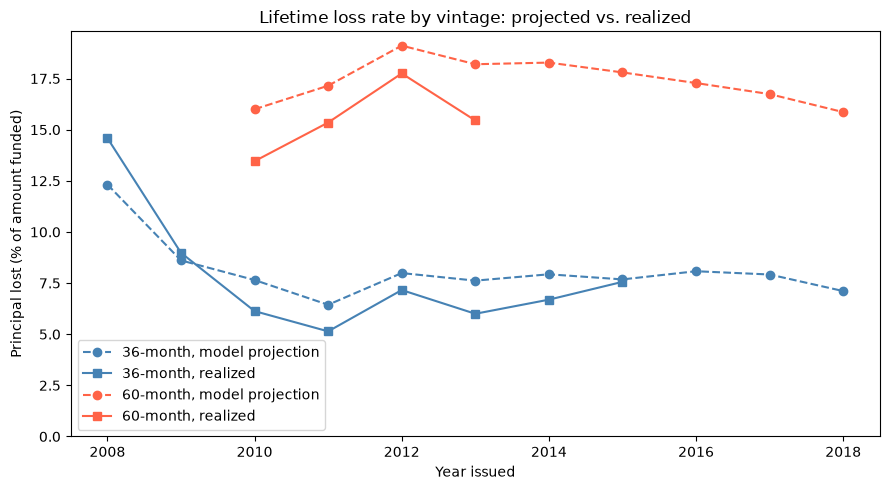

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for term, color in [(36, "steelblue"), (60, "tomato")]:
    rows = vintage[(vintage["term"] == term) & (vintage["loans"] >= 1000)]
    ax.plot(rows["issue_year"], rows["projected_loss_rate_pct"], color=color, linestyle="--", marker="o",
            label=f"{term}-month, model projection")
    ax.plot(rows["issue_year"], rows["realized_loss_rate_pct"], color=color, marker="s", label=f"{term}-month, realized")
ax.set_title("Lifetime loss rate by vintage: projected vs. realized")
ax.set_xlabel("Year issued")
ax.set_ylabel("Principal lost (% of amount funded)")
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "vintage_loss.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: vintages
The 2015 36-month vintage lines up (7.68% projected vs. 7.56% realized) because the model is now
calibrated to it. The 2010-2014 vintages came in below the projection: the recalibrated model reflects
2015-2016 credit conditions, which were worse. The 2008 vintage, hit by the financial crisis, was worse
than projected (14.6% vs. 12.3%). 60-month loans are projected to lose 16-18% of the amount funded, more
than twice the 7-8% for 36-month loans, in line with every matured 60-month vintage.

### Stress test: loans still running at the snapshot
Loans that had not reached full term by March 2019 are the book whose losses are still uncertain. Apply
three scenarios to their lifetime expected loss:

| Scenario | PD | LGD | Why |
|---|---|---|---|
| Baseline | recalibrated model | as estimated | today's best estimate |
| Mild recession | x 1.5 | + 5 points | |
| Severe recession | x 2.0 | + 10 points | 36-month loans from 2007-2008 defaulted about twice as often as those from 2010-2011 |

Recoveries usually fall in a downturn, so LGD rises along with PD.

In [8]:
SCENARIOS = {
    "Baseline": (1.0, 0.00),
    "Mild recession": (1.5, 0.05),
    "Severe recession": (2.0, 0.10),
}
ead_factor = {term: s["ead_factor"] for term, s in severity_recalibrated.items()}
lgd = {term: s["lgd"] for term, s in severity_recalibrated.items()}

open_book = loans[~loans["matured"]]
rows = []
for scenario, (pd_multiplier, lgd_add) in SCENARIOS.items():
    stressed_pd = (open_book["pd"] * pd_multiplier).clip(upper=1)
    stressed_lgd = (open_book["term"].map(lgd) + lgd_add).clip(upper=1)
    loss = stressed_pd * open_book["term"].map(ead_factor) * stressed_lgd * open_book["funded_amnt"]
    by_grade = pd.DataFrame({"grade": open_book["grade"], "funded": open_book["funded_amnt"], "expected_loss": loss})
    by_grade = by_grade.groupby("grade").sum().reset_index()
    by_grade.insert(0, "scenario", scenario)
    rows.append(by_grade)

stress = pd.concat(rows, ignore_index=True)
summary = stress.groupby("scenario", sort=False)[["funded", "expected_loss"]].sum()
summary["loss_rate_pct"] = (summary["expected_loss"] / summary["funded"] * 100).round(2)
summary[["funded", "expected_loss"]] = (summary[["funded", "expected_loss"]] / 1e9).round(2)
print(f"{len(open_book):,} loans still running")
summary.rename(columns={"funded": "funded_billions", "expected_loss": "expected_loss_billions"})

1,474,753 loans still running


,funded_billions,expected_loss_billions,loss_rate_pct
scenario,,,
Baseline,23.61,2.94,12.47
Mild recession,23.61,4.66,19.76
Severe recession,23.61,6.52,27.61


### Finding: stress test
1,474,753 loans (\$23.6 billion funded) had not reached full term at the snapshot. In the baseline they
are expected to lose \$2.94 billion over their lives (12.5% of the amount funded). A mild recession raises
that to \$4.66 billion (19.8%), and a severe one to \$6.52 billion (27.6%), more than double the baseline.
The loss rate is higher than for 36-month vintages because this book holds most of the 60-month loans,
which lose about 17% each.

### Approval strategy
Suppose a lender could only fund part of the 2015-2016 applications. Which loans should it take? Compare
two ways of ranking them, at every approval rate from 50% to 100%:
- **Sub-grade:** approve the best Lending Club sub-grades first.
- **Model:** approve the lowest predicted PD first.

These are real outcomes on loans the model never saw.

In [9]:
test = loans[recent].copy()
test["collected"] = test["total_pymnt"] - test["collection_recovery_fee"]


def policy_curve(rank_col, policy):
    ordered = test.sort_values(rank_col, kind="stable")
    rows = []
    for rate in np.arange(50, 101, 5):
        approved = ordered.iloc[: round(len(ordered) * rate / 100)]
        rows.append({
            "policy": policy,
            "approval_rate_pct": int(rate),
            "approved_loans": len(approved),
            "approved_funded_m": round(approved["funded_amnt"].sum() / 1e6, 1),
            "net_profit_m": round((approved["collected"].sum() - approved["funded_amnt"].sum()) / 1e6, 1),
            "max_pd_pct": round(approved["pd"].max() * 100, 1),
            "default_rate_pct": round(approved["bad"].mean() * 100, 2),
            "loss_rate_pct": round(approved["realized_loss"].sum() / approved["funded_amnt"].sum() * 100, 2),
            "net_return_pct": round((approved["collected"].sum() / approved["funded_amnt"].sum() - 1) * 100, 2),
        })
    return pd.DataFrame(rows)


strategy = pd.concat([policy_curve("sub_grade", "Sub-grade"), policy_curve("pd", "Model")], ignore_index=True)
strategy.pivot(index="approval_rate_pct", columns="policy", values=["default_rate_pct", "net_return_pct", "net_profit_m"])

default_rate_pct           net_return_pct            \
policy                       Model Sub-grade          Model Sub-grade   
approval_rate_pct                                                       
50                            7.78      8.36           7.24      6.78   
55                            8.38      8.94           7.22      6.80   
60                            8.97      9.58           7.19      6.74   
65                            9.58     10.14           7.14      6.72   
70                           10.22     10.77           7.07      6.66   
75                           10.92     11.37           6.96      6.63   
80                           11.60     12.02           6.86      6.55   
85                           12.27     12.67           6.76      6.46   
90                           13.08     13.35           6.56      6.36   
95                           14.02     14.14           6.29      6.19   
100                          15.18     15.18           5.90      5.90   

                  net_profit_m            
policy                   Model Sub-grade  
approval_rate_pct                         
50                       187.1     172.5  
55                       202.7     188.1  
60                       217.8     201.8  
65                       231.9     216.4  
70                       245.4     229.2  
75                       256.8     243.3  
80                       268.2     255.8  
85                       278.9     267.0  
90                       285.7     277.4  
95                       288.6     285.1  
100                      285.4     285.4

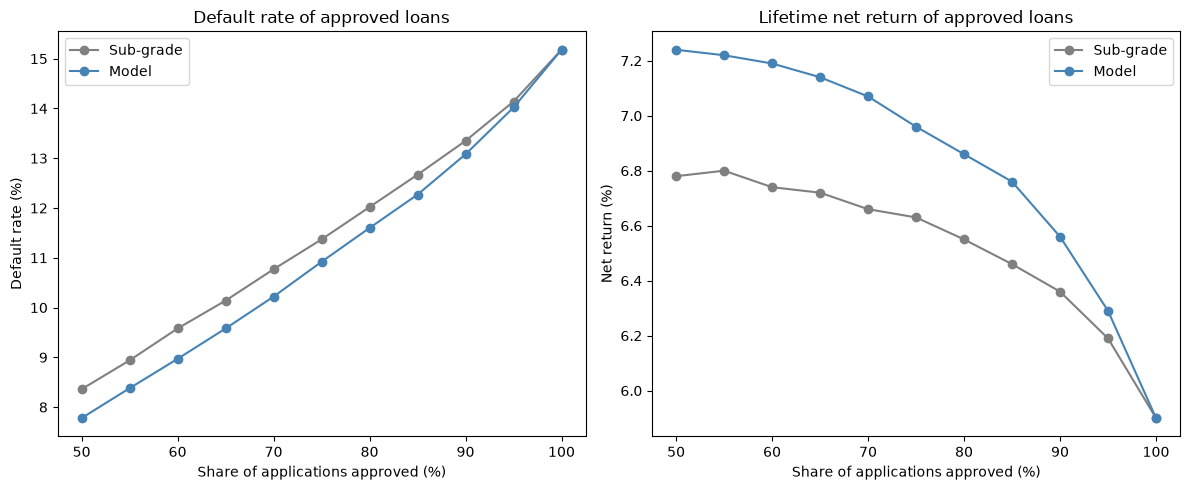

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for policy, color in [("Sub-grade", "gray"), ("Model", "steelblue")]:
    rows = strategy[strategy["policy"] == policy]
    axes[0].plot(rows["approval_rate_pct"], rows["default_rate_pct"], marker="o", color=color, label=policy)
    axes[1].plot(rows["approval_rate_pct"], rows["net_return_pct"], marker="o", color=color, label=policy)
axes[0].set_title("Default rate of approved loans")
axes[0].set_ylabel("Default rate (%)")
axes[1].set_title("Lifetime net return of approved loans")
axes[1].set_ylabel("Net return (%)")
for ax in axes:
    ax.set_xlabel("Share of applications approved (%)")
    ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "approval_strategy.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: strategy
Ranking by the model beats ranking by sub-grade at every approval rate. At 80% approval the model's
loans default 11.60% of the time vs. 12.02%, return 6.86% vs. 6.55%, and earn **\$12.4 million more**
(\$268.2M vs. \$255.8M).

The model also finds loans not worth making. Declining just the riskiest 5% by predicted PD would have
earned \$3.2 million *more* than approving everyone (\$288.6M vs. \$285.4M) while lending 5% less. Declining
by sub-grade never beats approving everyone. For these 2015-2016 loans, Lending Club underpriced its
riskiest borrowers: their extra interest did not cover their losses.

In [11]:
vintage_table = vintage[["issue_year", "term", "loans", "funded", "judged_share", "expected_loss",
                         "projected_loss_rate_pct", "realized_loss_rate_pct"]]
tables = {"vintage_loss": vintage_table, "stress_test": stress, "strategy_curve": strategy}
for name, table in tables.items():
    table.to_sql(name, engine, if_exists="replace", index=False)
    print(f"{name}: {len(table)} rows")

vintage_loss: 21 rows
stress_test: 21 rows
strategy_curve: 22 rows


### Summary
- **Backtest:** on 2015-2016 loans the original model expected 6.44% of the amount funded to be lost and
  7.90% was, a 23% shortfall that grows with risk.
- **Recalibration** (intercept and slope on the log-odds, loss severity on all matured defaults) brings the
  2015-2016 total within 3%. Grade-level losses for grades D-G remain understated.
- **Projected lifetime loss:** about 7-8% of the amount funded for 36-month vintages, 16-18% for 60-month.
- **Loans still running (\$23.6B):** \$2.94B expected loss in the baseline, \$4.66B in a mild recession,
  \$6.52B in a severe one.
- **Approval strategy:** at 80% approval the model cuts the default rate from 12.02% to 11.60% and earns
  \$12.4M more than ranking by sub-grade. Declining the riskiest 5% beats approving everyone.
- Saved `vintage_loss`, `stress_test`, and `strategy_curve` to PostgreSQL for the app.